# model_lineage — v1 → v5 모델 변천사 한눈 비교

피크 전력수요 SARIMAX 모델의 버전별 진화를 **하나의 그림 세트**로. 각 버전 스크립트의
산출 CSV에서 지표를 모아 `data/processed/arimax/model_lineage.csv`로 합본 후 시각화.

| ver | 스크립트 | 변경 | 채택 |
|---|---|---|---|
| v1 | `model_arimax.py` | 차수 그리드 + 16 exog | — |
| v2 | `model_arimax_v2.py` | 다중공선 정리 → 14 | — |
| **v3c** | `model_arimax_v3.py` | log+OR더미+비선형 | **주모델** |
| v4_ev | `model_arimax_v4_ev.py` | +전기차(무신호) | 미채택 |
| v5_greedy | `model_arimax_v5_greedy.py` | 변수선택 감사 | 분석 |
| v5 | `model_arimax_v5_simplify.py` | parsimony 14→10 | 간결변형 |

상세 계보: `src/MODELS.md` · 정리 로그: `docs/research_log/2026-05-31_1000_모델_변천사_v1_v5_정리.md`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
import seaborn as sns

warnings.filterwarnings("ignore")
# 한글 폰트 (eda/modeling.ipynb와 동일)
NOTO_PATH = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if NOTO_PATH.exists():
    font_manager.fontManager.addfont(str(NOTO_PATH))
KOR_FONT = "Noto Sans CJK JP"
mpl.rcParams["font.family"] = KOR_FONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", rc={"font.family": KOR_FONT})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
ARI = ROOT / "data" / "processed" / "arimax"
print("ARI:", ARI)

def mm(actual, pred):
    e = (actual - pred).abs()
    return float(e.mean()), float((e / actual).mean() * 100)

v1 = pd.read_csv(ARI / "forecast.csv", encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
v2 = pd.read_csv(ARI / "v2_forecast.csv", encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
v3 = pd.read_csv(ARI / "v3c_forecast.csv", encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
v5 = pd.read_csv(ARI / "v5c_forecast.csv", encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
r3 = pd.read_csv(ARI / "v3_results.csv", encoding="utf-8-sig").set_index("model")
r5 = pd.read_csv(ARI / "v5_results.csv", encoding="utf-8-sig").set_index("model")

def rec(ver, script, nexog, logt, aic, bic, act, one, roll, picp, skew, kurt, adopted, log):
    mo, mao = mm(act, one); mr, mar = mm(act, roll)
    return dict(version=ver, script=script, n_exog=nexog, log_target=logt,
                AIC=aic, BIC=bic, MAE_oneshot=mo, MAPE_oneshot=mao,
                MAE_rolling=mr, MAPE_rolling=mar, PI95_cov=picp,
                resid_skew=skew, resid_kurt=kurt, adopted=adopted, research_log=log)

rows = [
 rec("v1","model_arimax.py",16,False,np.nan,np.nan,v1["actual"],v1["arimax_oneshot"],v1["arimax_rolling"],
     95.34,np.nan,np.nan,"—","2026-05-26_1830"),
 rec("v2","model_arimax_v2.py",14,False,r3.loc["v2 (baseline)","AIC"],r3.loc["v2 (baseline)","BIC"],
     v2["actual"],v2["arimax_v2_oneshot"],v2["arimax_v2_rolling"],r3.loc["v2 (baseline)","PI95_cov_%"],
     r3.loc["v2 (baseline)","resid_skew"],r3.loc["v2 (baseline)","resid_kurt"],"—","2026-05-26_1734"),
 rec("v3c","model_arimax_v3.py",14,True,r3.loc["v3c log+OR+nonlinear","AIC"],r3.loc["v3c log+OR+nonlinear","BIC"],
     v3["actual"],v3["pred"],v3["rolling"],r3.loc["v3c log+OR+nonlinear","PI95_cov_%"],
     r3.loc["v3c log+OR+nonlinear","resid_skew"],r3.loc["v3c log+OR+nonlinear","resid_kurt"],"주모델","2026-05-26_1815"),
 rec("v5","model_arimax_v5_simplify.py",10,True,r5.loc["v5_bic_backward","AIC"],r5.loc["v5_bic_backward","BIC"],
     v5["actual"],v5["pred"],v5["rolling"],r5.loc["v5_bic_backward","PI95_cov_%"],
     r5.loc["v5_bic_backward","resid_skew"],r5.loc["v5_bic_backward","resid_kurt"],"간결변형","2026-05-30_1730"),
]
lin = pd.DataFrame(rows)
lin.to_csv(ARI / "model_lineage.csv", index=False, encoding="utf-8-sig")
print("저장:", ARI / "model_lineage.csv")
lin.round(2)

ARI: /home/jmlee/research/timeseries-final/data/processed/arimax
저장: /home/jmlee/research/timeseries-final/data/processed/arimax/model_lineage.csv


,version,script,n_exog,log_target,AIC,BIC,MAE_oneshot,MAPE_oneshot,MAE_rolling,MAPE_rolling,PI95_cov,resid_skew,resid_kurt,adopted,research_log
0,v1,model_arimax.py,16,False,NaN,NaN,3061.68,4.16,1522.56,2.09,95.34,NaN,NaN,—,2026-05-26_1830
1,v2,model_arimax_v2.py,14,False,99214.56,99346.67,2969.10,4.03,1515.79,2.08,97.53,-1.36,9.62,—,2026-05-26_1734
2,v3c,model_arimax_v3.py,14,True,-23830.96,-23698.85,2667.51,3.63,1357.31,1.87,95.34,-1.75,13.90,주모델,2026-05-26_1815
3,v5,model_arimax_v5_simplify.py,10,True,-23836.49,-23730.80,2670.44,3.64,1354.47,1.86,95.34,-1.76,13.92,간결변형,2026-05-30_1730


> v4_ev(전기차)는 **무신호로 미채택**이라 예측지표 행이 없음 — 표/그림은 실제 채택 라인
> (v1·v2·v3c·v5)만 비교. v4는 `notebooks/v4_ev.ipynb`·`v5_greedy.ipynb` 참조.

## 1. 버전별 MAE / MAPE 추이

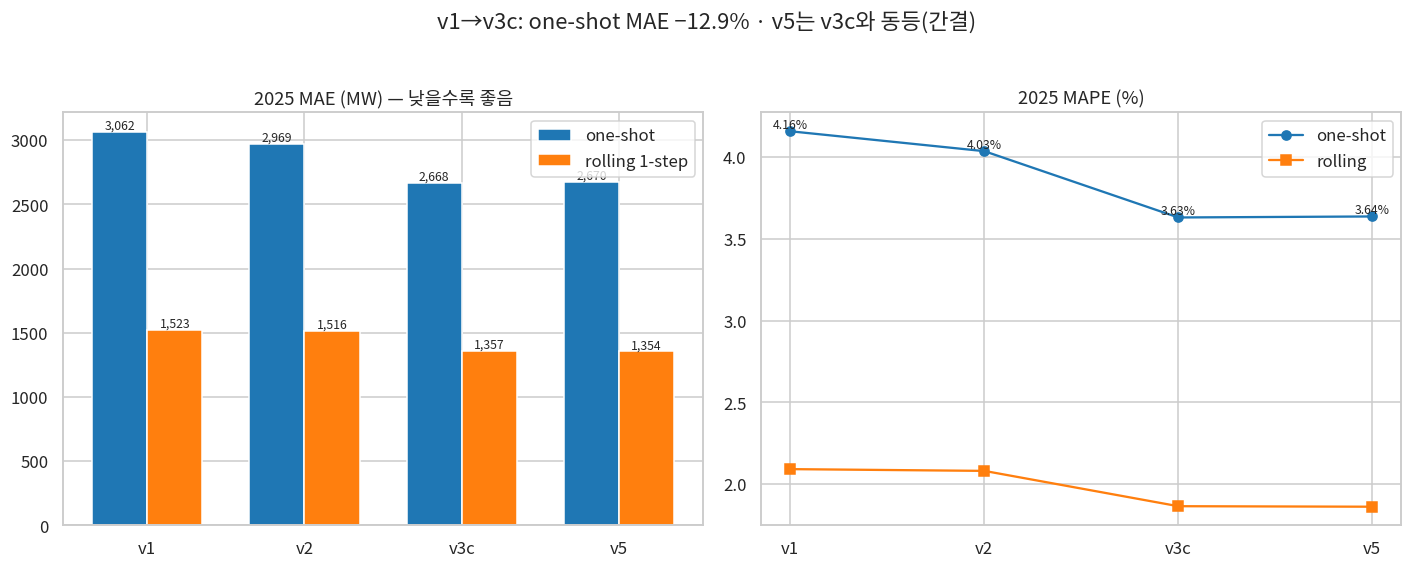

In [2]:
order = ["v1", "v2", "v3c", "v5"]
L = lin.set_index("version").loc[order]
x = np.arange(len(order)); w = 0.35
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(x - w/2, L["MAE_oneshot"], w, label="one-shot", color="tab:blue")
ax[0].bar(x + w/2, L["MAE_rolling"], w, label="rolling 1-step", color="tab:orange")
for i in x:
    ax[0].text(i - w/2, L["MAE_oneshot"].iloc[i], f"{L['MAE_oneshot'].iloc[i]:,.0f}", ha="center", va="bottom", fontsize=8)
    ax[0].text(i + w/2, L["MAE_rolling"].iloc[i], f"{L['MAE_rolling'].iloc[i]:,.0f}", ha="center", va="bottom", fontsize=8)
ax[0].set_xticks(x); ax[0].set_xticklabels(order); ax[0].set_title("2025 MAE (MW) — 낮을수록 좋음"); ax[0].legend()
ax[1].plot(order, L["MAPE_oneshot"], "o-", label="one-shot", color="tab:blue")
ax[1].plot(order, L["MAPE_rolling"], "s-", label="rolling", color="tab:orange")
for i in x:
    ax[1].text(i, L["MAPE_oneshot"].iloc[i], f"{L['MAPE_oneshot'].iloc[i]:.2f}%", ha="center", va="bottom", fontsize=8)
ax[1].set_title("2025 MAPE (%)"); ax[1].legend()
plt.suptitle("v1→v3c: one-shot MAE −12.9% · v5는 v3c와 동등(간결)", y=1.03)
plt.tight_layout(); plt.show()

## 2. 2025 예측 vs 실측 — 버전 오버레이 + 월별 MAE

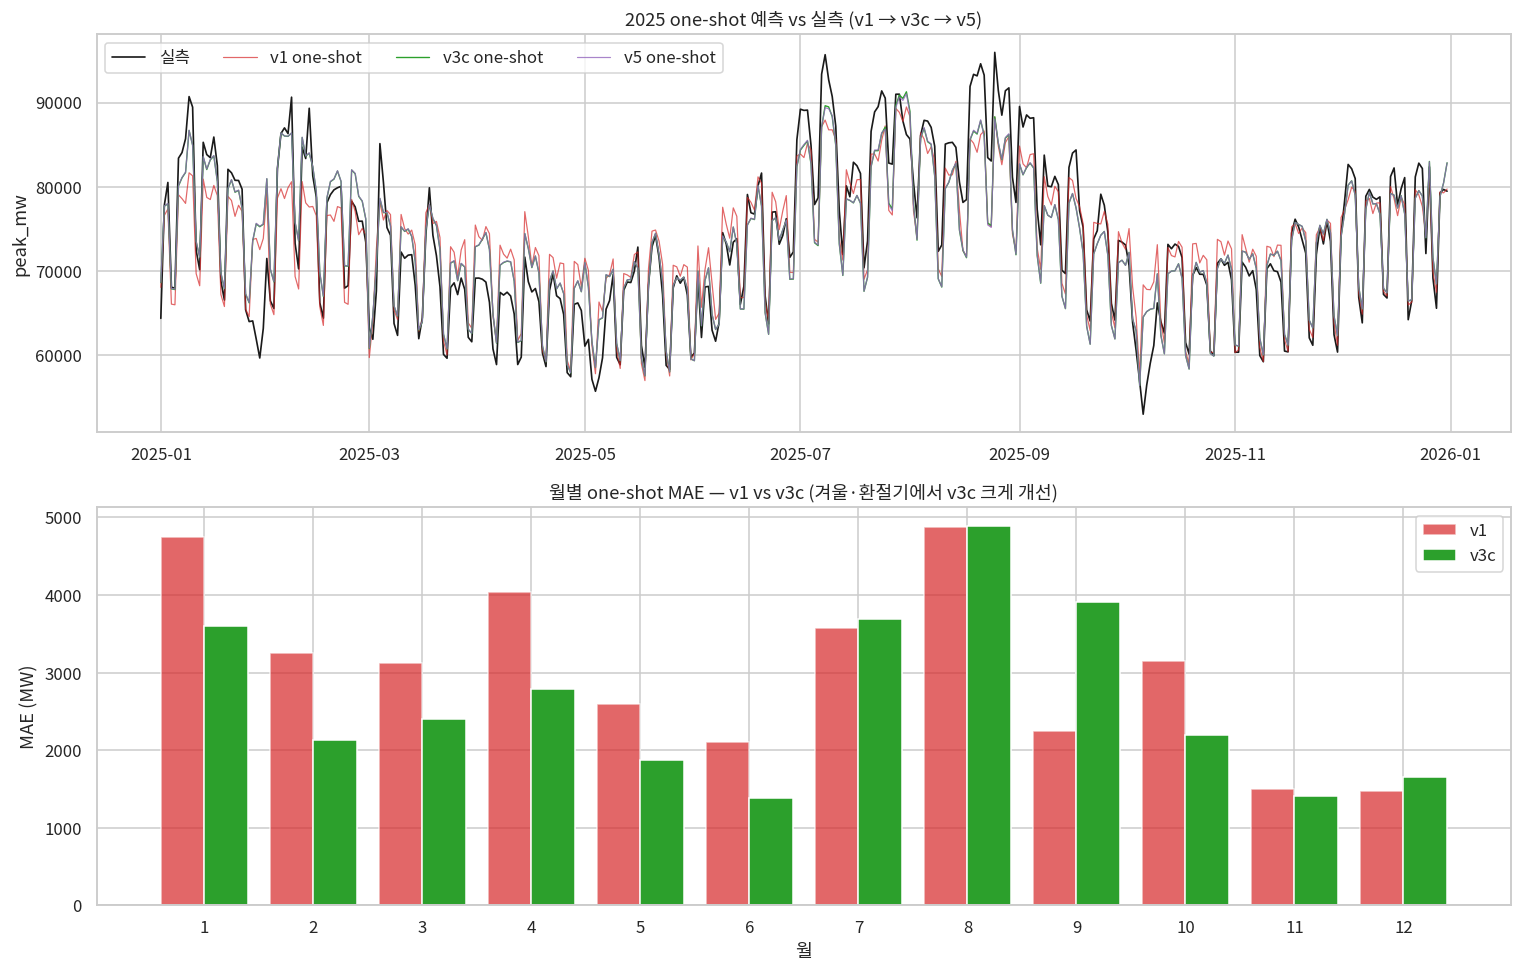

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
ax[0].plot(v1.index, v1["actual"], color="k", lw=1.1, label="실측")
ax[0].plot(v1.index, v1["arimax_oneshot"], color="tab:red", lw=.8, alpha=.7, label="v1 one-shot")
ax[0].plot(v3.index, v3["pred"], color="tab:green", lw=.9, label="v3c one-shot")
ax[0].plot(v5.index, v5["pred"], color="tab:purple", lw=.8, alpha=.8, label="v5 one-shot")
ax[0].set_title("2025 one-shot 예측 vs 실측 (v1 → v3c → v5)"); ax[0].set_ylabel("peak_mw"); ax[0].legend(ncol=4)
# 월별 one-shot MAE: v1 vs v3c
m = pd.DataFrame({"month": v1.index.month,
                  "v1": (v1["actual"] - v1["arimax_oneshot"]).abs().values,
                  "v3c": (v3["actual"] - v3["pred"]).abs().values}).groupby("month").mean()
xm = np.arange(1, 13)
ax[1].bar(xm - .2, m["v1"], .4, label="v1", color="tab:red", alpha=.7)
ax[1].bar(xm + .2, m["v3c"], .4, label="v3c", color="tab:green")
ax[1].set_xticks(xm); ax[1].set_title("월별 one-shot MAE — v1 vs v3c (겨울·환절기에서 v3c 크게 개선)")
ax[1].set_xlabel("월"); ax[1].set_ylabel("MAE (MW)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. 변수 개수 · 정보기준(AIC/BIC)

AIC/BIC는 **log 모델끼리만 비교 가능**(v1·v2는 원 스케일이라 제외). log 라인은
v3a→v3b→v3c→v5로 단조 개선.

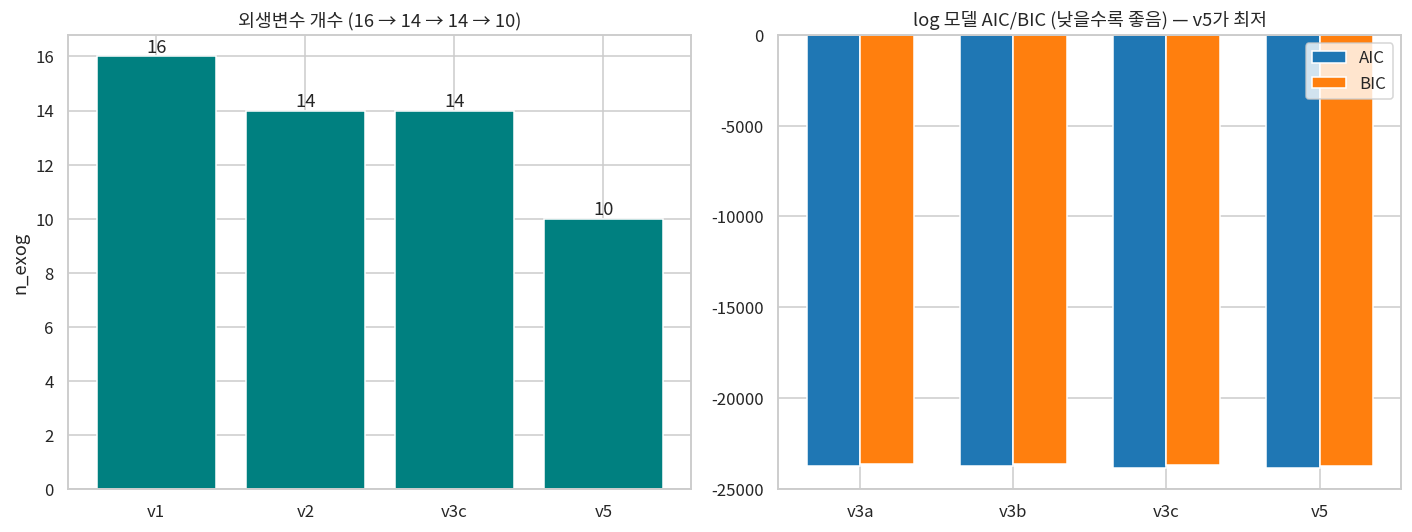

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].bar(order, L["n_exog"], color="teal")
for i, n in enumerate(L["n_exog"]):
    ax[0].text(i, n, f"{int(n)}", ha="center", va="bottom")
ax[0].set_title("외생변수 개수 (16 → 14 → 14 → 10)"); ax[0].set_ylabel("n_exog")
# log AIC/BIC: v3a, v3b, v3c, v5
logm = ["v3a log", "v3b log+OR더미", "v3c log+OR+nonlinear"]
aic = [r3.loc[k, "AIC"] for k in logm] + [r5.loc["v5_bic_backward", "AIC"]]
bic = [r3.loc[k, "BIC"] for k in logm] + [r5.loc["v5_bic_backward", "BIC"]]
lab = ["v3a", "v3b", "v3c", "v5"]
xx = np.arange(len(lab)); w = .35
ax[1].bar(xx - w/2, aic, w, label="AIC", color="tab:blue")
ax[1].bar(xx + w/2, bic, w, label="BIC", color="tab:orange")
ax[1].set_xticks(xx); ax[1].set_xticklabels(lab)
ax[1].set_title("log 모델 AIC/BIC (낮을수록 좋음) — v5가 최저"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. 잔차 진단 개선 (skew / kurtosis)

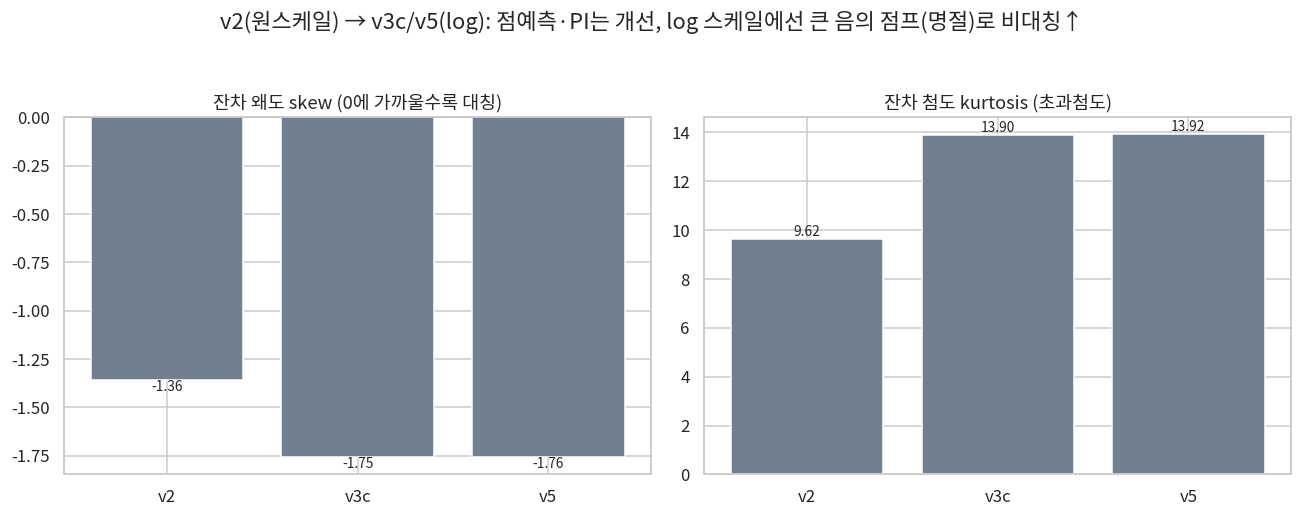

In [5]:
rr = lin.dropna(subset=["resid_skew"]).set_index("version")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(rr.index, rr["resid_skew"], color="slategray")
ax[0].set_title("잔차 왜도 skew (0에 가까울수록 대칭)"); ax[0].axhline(0, color="k", lw=.6)
ax[1].bar(rr.index, rr["resid_kurt"], color="slategray")
ax[1].set_title("잔차 첨도 kurtosis (초과첨도)")
for a, col in zip(ax, ["resid_skew", "resid_kurt"]):
    for i, v in enumerate(rr[col]):
        a.text(i, v, f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
plt.suptitle("v2(원스케일) → v3c/v5(log): 점예측·PI는 개선, log 스케일에선 큰 음의 점프(명절)로 비대칭↑", y=1.04)
plt.tight_layout(); plt.show()

### 요약

- **v1 → v3c**: 차수 확정 → 다중공선 정리 → log·OR더미·비선형 기온. one-shot MAE
  3,062 → 2,668(**−12.9%**), rolling 1,523 → 1,357(**−10.9%**). **주모델 = v3c.**
- **v4_ev**: 전기차는 3 window 전부 무신호 → 미채택. `v5_greedy`가 31변수 감사로
  v3c 잉여 4개를 식별.
- **v5**: 그 4개를 BIC로 제거 → 14→10, AIC/BIC·rolling 동등 이상. **검증된 간결변형**.
- 합본 데이터: `data/processed/arimax/model_lineage.csv` · 계보 SSOT: `src/MODELS.md`.